In order to convert the acceleration data (AD) given in bits into gravity, use this equation: 

Acceleration [g]: [(2*Range)/(2^Resolution)]*AD

In order to convert the rotation data (RD) given in bits into angular velocity, use this equation:

Angular velocity [°/s]: [(2*Range)/(2^Resolution)]*RD


Importamos las librerias.


In [21]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Define la ruta de un archivo (asegúrate de apuntar a tu carpeta de datos)
ruta_archivo = "Archivos caídas/F03_SA03_R03.txt"

# 2. Abre el archivo, elimina los ';' al final de cada fila y carga los números
with open(ruta_archivo, "r") as f:
  lineas_limpias = [linea.replace(";", "") for linea in f]

datos_crudos = np.loadtxt(lineas_limpias, delimiter=",")

# 3. Verificación de dimensiones
print("Forma de la matriz (filas, columnas):", datos_crudos.shape)
print("Primera fila de datos crudos:\n", datos_crudos[0])

Forma de la matriz (filas, columnas): (3000, 9)
Primera fila de datos crudos:
 [   4. -257.  -73.  -39.   71.    6.  -57. -988. -138.]


Las 3 primeras colummnas de los datos crudos, corresponden a los ejes X,Y,Z del acelerometro ADXL345, el cual entrega los datos en bits, con una resolucion de 13 bits y un rango de $\pm 16g$ 
para convertir los datos de aceleracion a unidades de gravedad, usamos la ecuacion: 
Acceleration [g]: [(2*Range)/(2^Resolution)]*AD, dada en el archivo README

Debemos aplicar una norma vectorial a los datos para obtener su magnitud, asi obtenemos una señal unica que no depende de la orientacion del sensor
$$a_{\text{total}}(t) = \sqrt{a_x(t)^2 + a_y(t)^2 + a_z(t)^2}$$

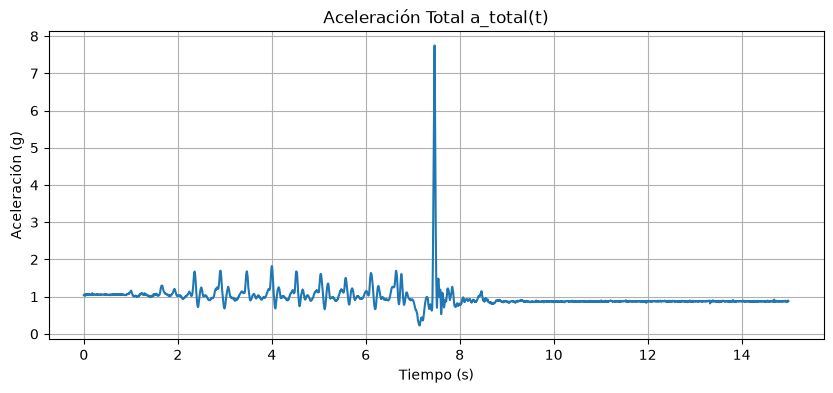

In [22]:
# 1. Factor de conversión del acelerómetro ADXL345 (según Readme: +-16g, 13 bits)
factor_g = (2 * 16) / (2**13)

# 2. Extraer columnas 0, 1 y 2 (X, Y, Z) y multiplicar por el factor
ax = datos_crudos[:, 0] * factor_g
ay = datos_crudos[:, 1] * factor_g
az = datos_crudos[:, 2] * factor_g

# 3. Calcular la magnitud de la aceleración total en cada instante t
a_total = np.sqrt(ax**2 + ay**2 + az**2)

# 4. Crear el vector de tiempo en segundos (frecuencia de muestreo = 200 Hz)

#Debido a que los archivos no nos dan los datos de los segundos, tenemos que construir el eje de tiempo a partir 
#de la cantidad de muestras y la frecuencia de muestreo. 
#La frecuencia de muestreo es de 200 Hz, es decir, 200 muestras por segundo. 
#Por lo tanto, el tiempo en segundos se puede calcular como el número de muestras dividido por la frecuencia de muestreo.
fs_muestreo = 200
tiempo = np.arange(len(a_total)) / fs_muestreo

# 5. Verificación visual en el dominio del tiempo
plt.figure(figsize=(10, 4))
plt.plot(tiempo, a_total)
plt.title("Aceleración Total a_total(t)")
plt.xlabel("Tiempo (s)")
plt.ylabel("Aceleración (g)")
plt.grid(True)
plt.show()

Ahora necesitamos eliminar la señal constante de la gravedad:
Para eso, primero calculamos el promedio aritmetico de toda la señal calculando un promedio de esta usando la funcion np.mean()
luego en cada muestra individual de a_total, es decir, las magnitudes en diferentes tiempo de la señal, se le resta el valor promedio hallado, que seria aproximadamente 1g correspondiente a la gravedad


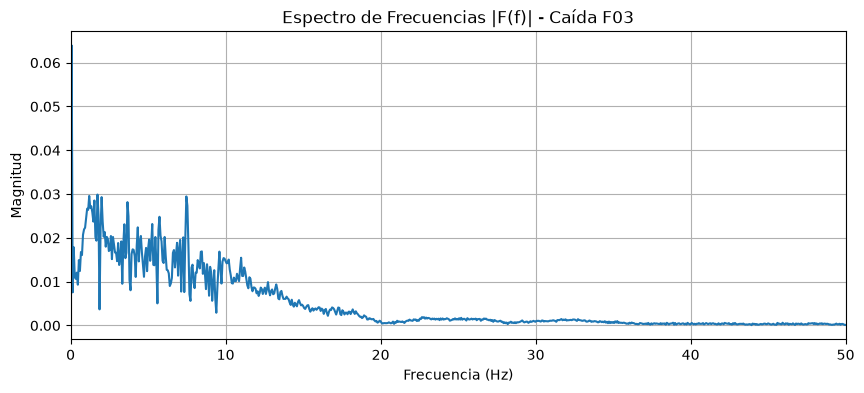

In [23]:
# 1. Quitar la componente constante de gravedad (0 Hz / DC)
a_sin_dc = a_total - np.mean(a_total)

# 2. Calcular la FFT para señales reales y su magnitud normalizada
N = len(a_sin_dc)
fft_compleja = np.fft.rfft(a_sin_dc)
magnitud = np.abs(fft_compleja) / N

# 3. Construir el eje X de frecuencias en Hz (sabemos que fs_muestreo = 200 Hz)
frecuencias = np.fft.rfftfreq(N, d=1 / fs_muestreo)

# 4. Graficar el espectro de frecuencias
plt.figure(figsize=(10, 4))
plt.plot(frecuencias, magnitud)
plt.title("Espectro de Frecuencias |F(f)| - Caída F03")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Magnitud")
plt.xlim(0, 50)  # Hacemos zoom de 0 a 50 Hz donde ocurre el movimiento humano
plt.grid(True)
plt.show()

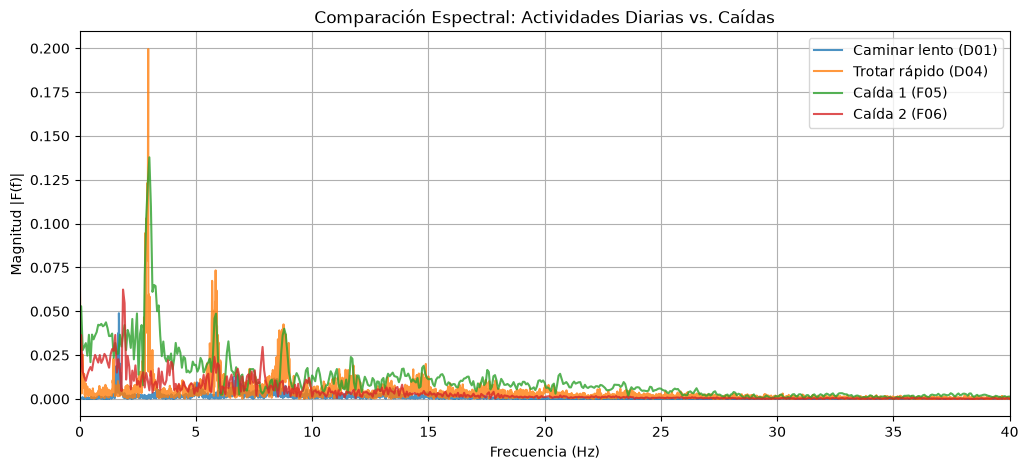

In [24]:
# 1. Creamos una función reutilizable que recibe la ruta de UN archivo y devuelve su FFT
def obtener_espectro(ruta):
  # Leer y limpiar los ';'
  with open(ruta, "r") as f:
    lineas = [linea.replace(";", "") for linea in f]
  datos = np.loadtxt(lineas, delimiter=",")

  # Convertir a g (ADXL345) y calcular magnitud total
  factor_g = (2 * 16) / (2**13)
  ax = datos[:, 0] * factor_g
  ay = datos[:, 1] * factor_g
  az = datos[:, 2] * factor_g
  a_total = np.sqrt(ax**2 + ay**2 + az**2)

  # Quitar gravedad constante (0 Hz) y calcular FFT normalizada
  a_sin_dc = a_total - np.mean(a_total)
  N = len(a_sin_dc)
  magnitud = np.abs(np.fft.rfft(a_sin_dc)) / N
  frecuencias = np.fft.rfftfreq(N, d=1 / 200)

  return frecuencias, magnitud


# 2. Diccionario con los 4 archivos clave de la Fase 1 (ajusta las rutas a tus carpetas)
archivos = {
    "Caminar lento (D01)": r"Archivos caídas/D01_SA01_R01.txt",
    "Trotar rápido (D04)": r"Archivos caídas/D04_SA03_R01.txt",
    "Caída 1 (F05)": r"Archivos caídas/F05_SA03_R01.txt",
    "Caída 2 (F06)": r"Archivos caídas/F06_SA03_R01.txt",
}

# 3. Graficar las 4 curvas superpuestas
plt.figure(figsize=(12, 5))

for etiqueta, ruta in archivos.items():
  freqs, mag = obtener_espectro(ruta)
  plt.plot(freqs, mag, label=etiqueta, alpha=0.8)

plt.title("Comparación Espectral: Actividades Diarias vs. Caídas")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Magnitud |F(f)|")
plt.xlim(0, 40)  # Zoom entre 0 y 40 Hz
plt.legend()
plt.grid(True)
plt.show()